In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from scipy.io import arff
import pandas as pd
data, meta = arff.loadarff("../data/raw/Training Dataset.arff")
df = pd.DataFrame(data)
for col in df.select_dtypes(['object']).columns:
    df[col] = df[col].str.decode('utf-8')
df.to_csv('../data/raw/initial_dataset.csv', index=False)     

In [3]:
df = pd.read_csv('../data/raw/initial_dataset.csv')

In [4]:
df

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11050,1,-1,1,-1,1,1,1,1,-1,-1,...,-1,-1,1,1,-1,-1,1,1,1,1
11051,-1,1,1,-1,-1,-1,1,-1,-1,-1,...,-1,1,1,1,1,1,1,-1,1,-1
11052,1,-1,1,1,1,-1,1,-1,-1,1,...,1,1,1,1,1,-1,1,0,1,-1
11053,-1,-1,1,1,1,-1,-1,-1,1,-1,...,-1,1,1,1,1,-1,1,1,1,-1


In [5]:
df = df.apply(pd.to_numeric)

In [6]:
df.head()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [7]:
df.shape

(11055, 31)

In [8]:
df.columns

Index(['having_IP_Address', 'URL_Length', 'Shortining_Service',
       'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix',
       'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length',
       'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor',
       'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL',
       'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe',
       'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank',
       'Google_Index', 'Links_pointing_to_page', 'Statistical_report',
       'Result'],
      dtype='object')

In [9]:
df.isnull().sum()

having_IP_Address              0
URL_Length                     0
Shortining_Service             0
having_At_Symbol               0
double_slash_redirecting       0
Prefix_Suffix                  0
having_Sub_Domain              0
SSLfinal_State                 0
Domain_registeration_length    0
Favicon                        0
port                           0
HTTPS_token                    0
Request_URL                    0
URL_of_Anchor                  0
Links_in_tags                  0
SFH                            0
Submitting_to_email            0
Abnormal_URL                   0
Redirect                       0
on_mouseover                   0
RightClick                     0
popUpWidnow                    0
Iframe                         0
age_of_domain                  0
DNSRecord                      0
web_traffic                    0
Page_Rank                      0
Google_Index                   0
Links_pointing_to_page         0
Statistical_report             0
Result    

In [10]:
df['Result'].value_counts(normalize=True)*100

Result
 1    55.694256
-1    44.305744
Name: proportion, dtype: float64

In [11]:
df.duplicated().sum()

np.int64(5206)

In [12]:
print("Total rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Unique rows:", df.drop_duplicates().shape[0])

Total rows: 11055
Duplicate rows: 5206
Unique rows: 5849


In [13]:
dup = df[df.duplicated(keep=False)]

dup.groupby(list(df.columns[:-1]))["Result"].nunique().value_counts()

Result
1    2579
2      29
Name: count, dtype: int64

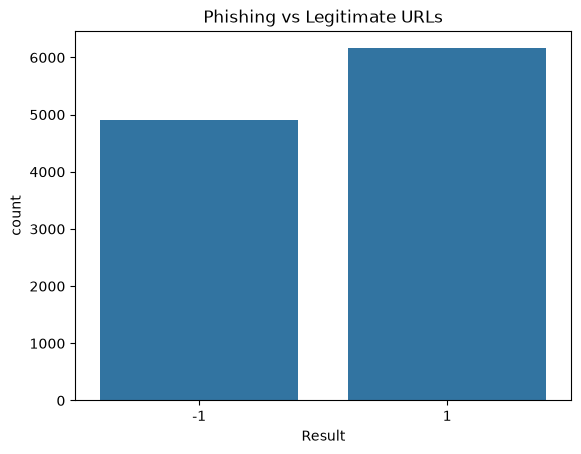

In [14]:
sns.countplot(data=df, x="Result")
plt.title("Phishing vs Legitimate URLs")
plt.show()

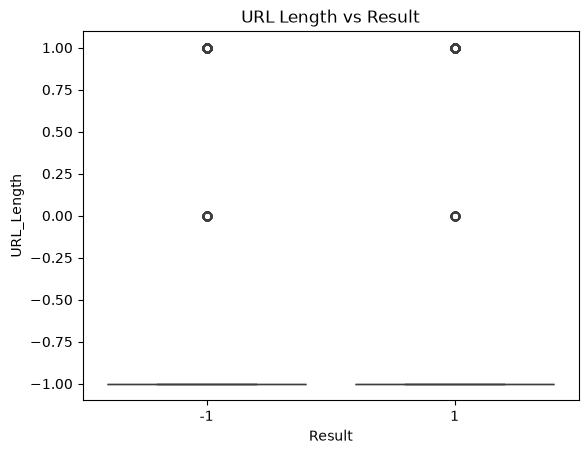

In [15]:
sns.boxplot(data=df, x="Result", y="URL_Length")
plt.title("URL Length vs Result")
plt.show()

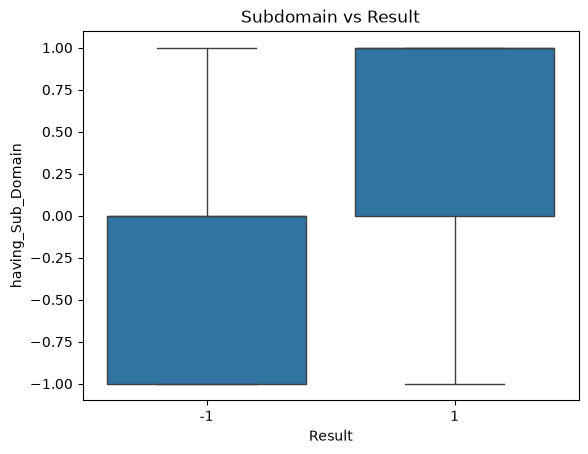

In [16]:
sns.boxplot(data=df, x="Result", y="having_Sub_Domain")
plt.title("Subdomain vs Result")
plt.show()

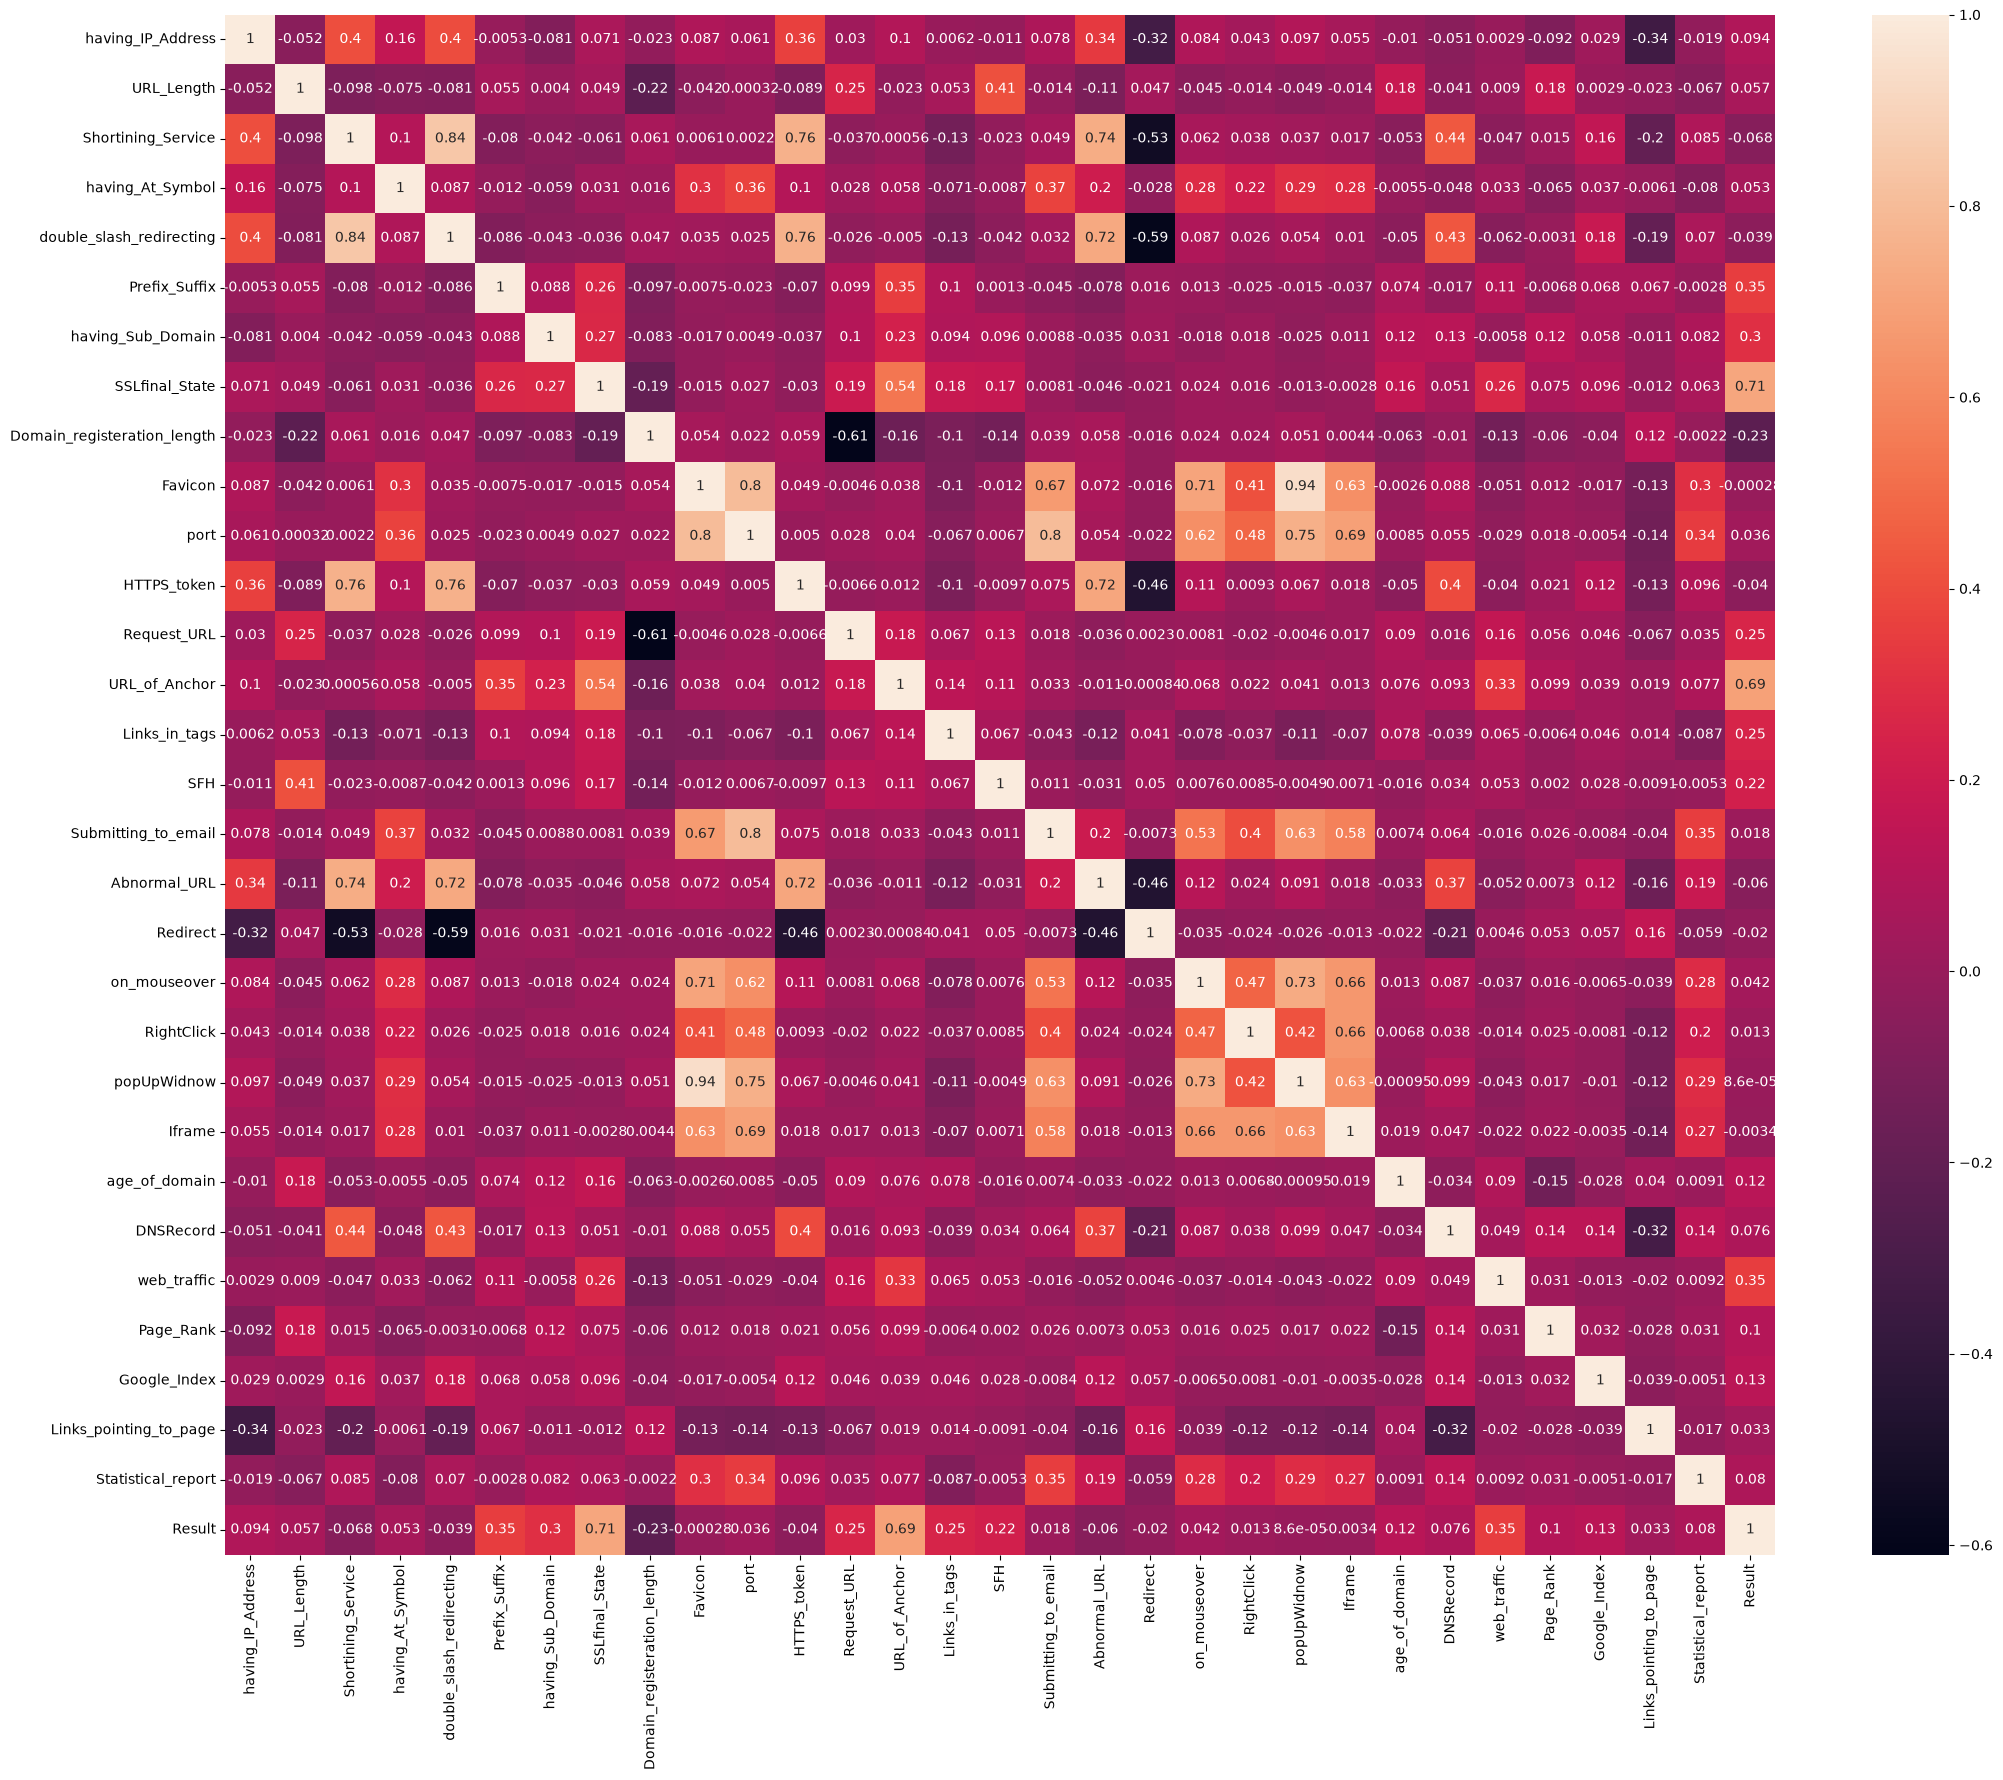

In [17]:
plt.figure(figsize=(25, 20))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
)

plt.show()

In [18]:
def corr(dataset , threshold):
    col_corr = set()
    corr_matrix = dataset.corr()
    for i in range(len(corr_matrix.columns)):
        for j in range(i):
           if abs(corr_matrix.iloc[i, j]) > threshold:
                col_corr.add(corr_matrix.columns[i])
    return col_corr           

In [19]:
corr_features=corr(df,0.75)

In [20]:
corr_features

{'HTTPS_token',
 'Submitting_to_email',
 'double_slash_redirecting',
 'popUpWidnow',
 'port'}

In [21]:
print(df.shape)
print(df.columns.tolist())
print(df["Result"].value_counts())
print(df.isnull().sum().sum())
print(df.duplicated().sum())

(11055, 31)
['having_IP_Address', 'URL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report', 'Result']
Result
 1    6157
-1    4898
Name: count, dtype: int64
0
5206


In [22]:
df.head()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [23]:
df.dtypes

having_IP_Address              int64
URL_Length                     int64
Shortining_Service             int64
having_At_Symbol               int64
double_slash_redirecting       int64
Prefix_Suffix                  int64
having_Sub_Domain              int64
SSLfinal_State                 int64
Domain_registeration_length    int64
Favicon                        int64
port                           int64
HTTPS_token                    int64
Request_URL                    int64
URL_of_Anchor                  int64
Links_in_tags                  int64
SFH                            int64
Submitting_to_email            int64
Abnormal_URL                   int64
Redirect                       int64
on_mouseover                   int64
RightClick                     int64
popUpWidnow                    int64
Iframe                         int64
age_of_domain                  int64
DNSRecord                      int64
web_traffic                    int64
Page_Rank                      int64
G

In [24]:
features = df.columns[:-1]

In [25]:
features

Index(['having_IP_Address', 'URL_Length', 'Shortining_Service',
       'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix',
       'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length',
       'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor',
       'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL',
       'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe',
       'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank',
       'Google_Index', 'Links_pointing_to_page', 'Statistical_report'],
      dtype='object')

In [26]:
features_info = pd.DataFrame({
    "features" : df.columns,
    "unique_values" : [df[col].nunique() for col in df.columns],
    "missing" : [df[col].isnull().sum() for col in df.columns]
})

In [27]:
features_info

,features,unique_values,missing
0,having_IP_Address,2,0
1,URL_Length,3,0
2,Shortining_Service,2,0
3,having_At_Symbol,2,0
4,double_slash_redirecting,2,0
5,Prefix_Suffix,2,0
6,having_Sub_Domain,3,0
7,SSLfinal_State,3,0
8,Domain_registeration_length,2,0
9,Favicon,2,0


In [28]:
features_corr = df.corr()["Result"].sort_values()

In [29]:
features_corr

Domain_registeration_length   -0.225789
Shortining_Service            -0.067966
Abnormal_URL                  -0.060488
HTTPS_token                   -0.039854
double_slash_redirecting      -0.038608
Redirect                      -0.020113
Iframe                        -0.003394
Favicon                       -0.000280
popUpWidnow                    0.000086
RightClick                     0.012653
Submitting_to_email            0.018249
Links_pointing_to_page         0.032574
port                           0.036419
on_mouseover                   0.041838
having_At_Symbol               0.052948
URL_Length                     0.057430
DNSRecord                      0.075718
Statistical_report             0.079857
having_IP_Address              0.094160
Page_Rank                      0.104645
age_of_domain                  0.121496
Google_Index                   0.128950
SFH                            0.221419
Links_in_tags                  0.248229
Request_URL                    0.253372


In [30]:
c = 0;
for col in features_corr.index:
    if features_corr[(col)] > 0.7 and features_corr[(col)] < 0.9:
        c += 1


In [31]:
c

1

In [32]:
features_corr.abs().sort_values()

popUpWidnow                    0.000086
Favicon                        0.000280
Iframe                         0.003394
RightClick                     0.012653
Submitting_to_email            0.018249
Redirect                       0.020113
Links_pointing_to_page         0.032574
port                           0.036419
double_slash_redirecting       0.038608
HTTPS_token                    0.039854
on_mouseover                   0.041838
having_At_Symbol               0.052948
URL_Length                     0.057430
Abnormal_URL                   0.060488
Shortining_Service             0.067966
DNSRecord                      0.075718
Statistical_report             0.079857
having_IP_Address              0.094160
Page_Rank                      0.104645
age_of_domain                  0.121496
Google_Index                   0.128950
SFH                            0.221419
Domain_registeration_length    0.225789
Links_in_tags                  0.248229
Request_URL                    0.253372


In [33]:
df["having_IP_Address"].value_counts()

having_IP_Address
 1    7262
-1    3793
Name: count, dtype: int64

In [34]:
pd.crosstab(
    df["having_IP_Address"],df["Result"],normalize="index"
)*100

Result,-1,1
having_IP_Address,,
-1,50.777748,49.222252
1,40.925365,59.074635


In [35]:
df.dtypes

having_IP_Address              int64
URL_Length                     int64
Shortining_Service             int64
having_At_Symbol               int64
double_slash_redirecting       int64
Prefix_Suffix                  int64
having_Sub_Domain              int64
SSLfinal_State                 int64
Domain_registeration_length    int64
Favicon                        int64
port                           int64
HTTPS_token                    int64
Request_URL                    int64
URL_of_Anchor                  int64
Links_in_tags                  int64
SFH                            int64
Submitting_to_email            int64
Abnormal_URL                   int64
Redirect                       int64
on_mouseover                   int64
RightClick                     int64
popUpWidnow                    int64
Iframe                         int64
age_of_domain                  int64
DNSRecord                      int64
web_traffic                    int64
Page_Rank                      int64
G

In [36]:
x = df.drop(['Result'], axis=1)
y = df['Result']

In [37]:
from sklearn.model_selection import train_test_split
x_train , x_test , y_train , y_test = train_test_split(x,y,test_size = 0.2 , random_state=42,stratify=y)

In [38]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [39]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=1000)
lr.fit(x_train,y_train)
y_pred = lr.predict(x_test)

In [40]:
from sklearn.metrics import accuracy_score , precision_score , recall_score , f1_score , confusion_matrix

print("accuracy is " , accuracy_score(y_test , y_pred))
print("precision score is " , precision_score(y_test , y_pred))
print("recall score  is " , recall_score(y_test , y_pred))
print("f1 score is " , f1_score(   y_test , y_pred))
print("confusion matrix is " , confusion_matrix(y_test , y_pred))

accuracy is  0.9285391225689733
precision score is  0.9234411996842936
recall score  is  0.950446791226645
f1 score is  0.9367493995196157
confusion matrix is  [[ 883   97]
 [  61 1170]]


In [41]:
from sklearn.model_selection import GridSearchCV

In [42]:
param_grid = {
    "C" : [0.01,0.1,1,10,100],
    "solver" : ["liblinear", "lbfgs"],
    "class_weight": [None, "balanced"]
}

In [43]:
grid = GridSearchCV(
    LogisticRegression(max_iter=1000),
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs= -1
)

In [44]:
grid.fit(x_train, y_train)

print(grid.best_params_)

print(grid.best_score_)

{'C': 0.1, 'class_weight': None, 'solver': 'lbfgs'}
0.9352633728827392


In [45]:
df1 = pd.read_csv(
    "../data/raw/urlset.csv",
    encoding="latin1",
    on_bad_lines="skip"
)

In [46]:
df1

,domain,ranking,mld_res,mld.ps_res,card_rem,ratio_Rrem,ratio_Arem,jaccard_RR,jaccard_RA,jaccard_AR,jaccard_AA,jaccard_ARrd,jaccard_ARrem,label
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,10000000,1.0,0.0,18,107.611111,107.277778,0.000000,0.000000,0.000000,0.000000,0.800000,0.795729,1.0
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,10000000,0.0,0.0,11,150.636364,152.272727,0.000000,0.000000,0.000000,0.000000,0.000000,0.768577,1.0
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,10000000,0.0,0.0,14,73.500000,72.642857,0.000000,0.000000,0.000000,0.000000,0.000000,0.726582,1.0
3,mail.printakid.com/www.online.americanexpress....,10000000,0.0,0.0,6,562.000000,590.666667,0.000000,0.000000,0.000000,0.000000,0.000000,0.859640,1.0
4,thewhiskeydregs.com/wp-content/themes/widescre...,10000000,0.0,0.0,8,29.000000,24.125000,0.000000,0.000000,0.000000,0.000000,0.000000,0.748971,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95908,xbox360.ign.com/objects/850/850402.html,339,1.0,1.0,2,142.500000,141.000000,0.009009,0.009091,0.006536,0.006601,0.450980,0.846906,0.0
95909,games.teamxbox.com/xbox-360/1860/Dead-Space/,63029,1.0,0.0,3,114.000000,128.333333,0.002899,0.002577,0.002907,0.002584,0.750000,0.714623,0.0
95910,www.gamespot.com/xbox360/action/deadspace/,753,1.0,1.0,3,91.000000,101.333333,0.000000,0.003106,0.000000,0.000000,0.111111,0.648571,0.0
95911,en.wikipedia.org/wiki/Dead_Space_(video_game),6,1.0,1.0,4,682.000000,744.250000,0.033075,0.029412,0.030250,0.029145,0.809735,0.840323,0.0


In [47]:
print(df1.shape)
print(df1.columns.tolist())
print(df1.isnull().sum())
print(df1["label"].value_counts())
print(df1.duplicated().sum())

(95913, 14)
['domain', 'ranking', 'mld_res', 'mld.ps_res', 'card_rem', 'ratio_Rrem', 'ratio_Arem', 'jaccard_RR', 'jaccard_RA', 'jaccard_AR', 'jaccard_AA', 'jaccard_ARrd', 'jaccard_ARrem', 'label']
domain           0
ranking          0
mld_res          0
mld.ps_res       0
card_rem         0
ratio_Rrem       0
ratio_Arem       0
jaccard_RR       0
jaccard_RA       0
jaccard_AR       0
jaccard_AA       0
jaccard_ARrd     0
jaccard_ARrem    0
label            0
dtype: int64
label
0.0    48009
1.0    47904
Name: count, dtype: int64
1


In [48]:
print(df1["domain"].head(10))

0    nobell.it/70ffb52d079109dca5664cce6f317373782/...
1    www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...
2    serviciosbys.com/paypal.cgi.bin.get-into.herf....
3    mail.printakid.com/www.online.americanexpress....
4    thewhiskeydregs.com/wp-content/themes/widescre...
5                 smilesvoegol.servebbs.org/voegol.php
6    premierpaymentprocessing.com/includes/boleto-2...
7    myxxxcollection.com/v1/js/jih321/bpd.com.do/do...
8                                  super1000.info/docs
9    horizonsgallery.com/js/bin/ssl1/_id/www.paypal...
Name: domain, dtype: object


In [49]:
df1.head()

,domain,ranking,mld_res,mld.ps_res,card_rem,ratio_Rrem,ratio_Arem,jaccard_RR,jaccard_RA,jaccard_AR,jaccard_AA,jaccard_ARrd,jaccard_ARrem,label
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,10000000,1.0,0.0,18,107.611111,107.277778,0.0,0.0,0.0,0.0,0.8,0.795729,1.0
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,10000000,0.0,0.0,11,150.636364,152.272727,0.0,0.0,0.0,0.0,0.0,0.768577,1.0
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,10000000,0.0,0.0,14,73.500000,72.642857,0.0,0.0,0.0,0.0,0.0,0.726582,1.0
3,mail.printakid.com/www.online.americanexpress....,10000000,0.0,0.0,6,562.000000,590.666667,0.0,0.0,0.0,0.0,0.0,0.859640,1.0
4,thewhiskeydregs.com/wp-content/themes/widescre...,10000000,0.0,0.0,8,29.000000,24.125000,0.0,0.0,0.0,0.0,0.0,0.748971,1.0


In [50]:
df1 = df1.dropna(subset=["label"])
df1.shape

(95913, 14)

In [51]:
print(df1.shape)
print(df1["label"].isnull().sum())

(95913, 14)
0


In [52]:
df1['mld.card'].unique().shape

KeyError: 'mld.card'